<a href="https://colab.research.google.com/github/bantupallirenukasai-wq/Macular-GNN/blob/main/objective_3_scopus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()


TypeError: 'NoneType' object is not subscriptable

In [ ]:
!apt-get install unrar


In [ ]:
!unrar x "All ARMD images.rar"  ARMD_Images/


In [ ]:
import glob

# Match all supported image formats
image_paths = glob.glob("ARMD_Images/**/*.*", recursive=True)

# Filter only image extensions
valid_ext = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

image_paths = [img for img in image_paths if img.lower().endswith(valid_ext)]

print("Total number of images found:", len(image_paths))
image_paths[:10]  # show first 10


Total number of images found: 511


['ARMD_Images/All ARMD images/0_RFiMD_26_ARMD.png',
 'ARMD_Images/All ARMD images/0_ORID19_26_ARMD.png',
 'ARMD_Images/All ARMD images/0_ORID19_99_ARMD.png',
 'ARMD_Images/All ARMD images/0_1kIM_34_ARMD.png',
 'ARMD_Images/All ARMD images/0_RFiMD_29_ARMD.png',
 'ARMD_Images/All ARMD images/0_ORID19_33_ARMD.png',
 'ARMD_Images/All ARMD images/0_1kIM_35_ARMD.png',
 'ARMD_Images/All ARMD images/0_RFiMD_54_ARMD.png',
 'ARMD_Images/All ARMD images/0_ORID19_42_ARMD.png',
 'ARMD_Images/All ARMD images/0_1kIM_33_ARMD.png']

In [ ]:
import cv2

images = [cv2.imread(path) for path in image_paths]
print("Images successfully loaded:", len(images))


Images successfully loaded: 511


Total images found: 511


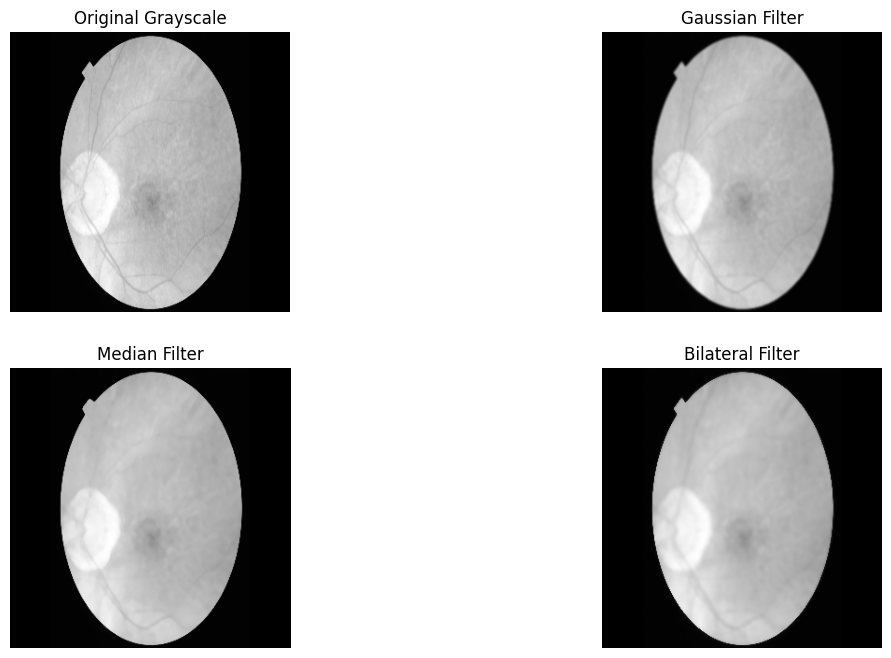

In [ ]:
import cv2
import glob
import os
import matplotlib.pyplot as plt

# Path where your extracted dataset is stored
DATASET_PATH = "ARMD_Images"

# Collect all image file paths
valid_ext = (".jpg", ".jpeg", ".png", ".bmp", ".tif")
image_paths = [p for p in glob.glob(DATASET_PATH + "/**/*.*", recursive=True)
               if p.lower().endswith(valid_ext)]

print("Total images found:", len(image_paths))

# Folder to store filtered images (optional)
os.makedirs("Filtered_Output", exist_ok=True)


def apply_filters(img):
    """Apply 3 spatial filters to the input image"""

    # Convert to grayscale (OCT images benefit from this)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    gaussian = cv2.GaussianBlur(gray, (5, 5), 0)
    median = cv2.medianBlur(gray, 5)
    bilateral = cv2.bilateralFilter(gray, 7, 75, 75)

    return gray, gaussian, median, bilateral


# Process first image as example output
sample_path = image_paths[0]
sample_img = cv2.imread(sample_path)

gray, gaussian, median, bilateral = apply_filters(sample_img)

# Show output
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.title("Original Grayscale")
plt.imshow(gray, cmap="gray")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.title("Gaussian Filter")
plt.imshow(gaussian, cmap="gray")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.title("Median Filter")
plt.imshow(median, cmap="gray")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.title("Bilateral Filter")
plt.imshow(bilateral, cmap="gray")
plt.axis("off")

plt.show()


# OPTIONAL — Save all filtered images
SAVE = False  # change to True to save all outputs

if SAVE:
    for path in image_paths:
        img = cv2.imread(path)
        gray, g, m, b = apply_filters(img)

        filename = os.path.basename(path)
        cv2.imwrite(f"Filtered_Output/{filename}_gaussian.png", g)
        cv2.imwrite(f"Filtered_Output/{filename}_median.png", m)
        cv2.imwrite(f"Filtered_Output/{filename}_bilateral.png", b)

    print("Filtered images saved to /Filtered_Output/")


In [ ]:
# Install (Colab): uncomment if needed
# !pip install torch torchvision

import torch
import torch.nn as nn
import torch.nn.functional as F

class PatchEmbed(nn.Module):
    """Split image into patches and project to embedding dim."""
    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=768):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        assert img_size % patch_size == 0, "img_size must be divisible by patch_size"
        self.num_patches = (img_size // patch_size) ** 2
        # Use Conv2d to perform patching + linear projection in one op
        self.proj = nn.Conv2d(in_chans, embed_dim,
                              kernel_size=patch_size,
                              stride=patch_size)

    def forward(self, x):
        # x: (B, C, H, W)
        x = self.proj(x)           # (B, embed_dim, H/ps, W/ps)
        x = x.flatten(2)           # (B, embed_dim, N_patches)
        x = x.transpose(1, 2)      # (B, N_patches, embed_dim)
        return x                   # patch embeddings


class ViTEncoder(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=3,
                 embed_dim=256, depth=6, num_heads=8, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches

        # optional CLS token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

        # positional encoding
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

        # build transformer encoder (stack of encoder layers)
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim,
                                                   nhead=num_heads,
                                                   dim_feedforward=int(embed_dim * mlp_ratio),
                                                   dropout=dropout,
                                                   activation='gelu',
                                                   batch_first=True)  # batch_first=True for (B, N, C)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        # final projection/classifier (if needed)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        """x: (B, C, H, W)"""
        B = x.size(0)
        x = self.patch_embed(x)                 # (B, N, embed_dim)
        # prepend cls token
        cls_tokens = self.cls_token.expand(B, -1, -1)  # (B,1,embed_dim)
        x = torch.cat((cls_tokens, x), dim=1)         # (B, N+1, embed_dim)
        x = x + self.pos_embed                         # add positional encoding

        # transformer encoder
        x = self.transformer(x)                        # (B, N+1, embed_dim)
        x = self.norm(x)

        # Feature vector: typically use CLS token output
        cls_output = x[:, 0]           # (B, embed_dim)
        # Optionally, you can also use mean pooling: x[:,1:,:].mean(dim=1)
        return cls_output, x           # return cls token and full token representations


if __name__ == "__main__":
    # example usage / test run
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ViTEncoder(img_size=224, patch_size=16, in_chans=3,
                       embed_dim=256, depth=6, num_heads=8, mlp_ratio=4.0).to(device)

    # create a dummy batch (1 image)
    dummy_img = torch.randn(1, 3, 224, 224, device=device)

    cls_feat, all_tokens = model(dummy_img)

    print("Patch embedding -> number of patches:", model.patch_embed.num_patches)
    print("All token tensor shape (B, N+1, embed_dim):", all_tokens.shape)
    print("CLS feature vector shape (B, embed_dim):", cls_feat.shape)

    # print a small slice for inspection (first 10 values)
    print("CLS feature vector (first sample, first 10 values):")
    print(cls_feat[0, :10].detach().cpu().numpy())


Patch embedding -> number of patches: 196
All token tensor shape (B, N+1, embed_dim): torch.Size([1, 197, 256])
CLS feature vector shape (B, embed_dim): torch.Size([1, 256])
CLS feature vector (first sample, first 10 values):
[-1.3211557  -1.7350711   0.08364477 -0.3444836   2.2590559   0.50660133
 -1.297835   -0.41432473  0.07419978 -0.3283151 ]


In [ ]:
import numpy as np

# Example: 196 patches, each with 1024 features (from CNN)
patch_features = np.random.rand(196, 1024)

# Example: Additional biomarkers/features (e.g., thickness, clinical data)
clinical_features = np.random.rand(196, 10)  # 10 other multimodal features

# Combine into one feature set (early fusion)
fused_features = np.concatenate([patch_features, clinical_features], axis=1)
print("Fused feature shape:", fused_features.shape)


Fused feature shape: (196, 1034)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

# Example labels: 0 = normal, 1 = AMD
labels = np.random.randint(0, 2, 196)
labels_categorical = to_categorical(labels)

model = Sequential([
    Dense(512, input_dim=fused_features.shape[1], activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(2, activation='softmax')  # 2 classes
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(fused_features, labels_categorical, epochs=50, batch_size=16)


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6054 - loss: 0.9818
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5163 - loss: 0.8604
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5693 - loss: 0.8040
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5444 - loss: 0.7282
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5934 - loss: 0.7190
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6022 - loss: 0.6840
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5838 - loss: 0.6905
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6133 - loss: 0.6634
Epoch 9/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7091 - loss: 0.5617
Epoch 10/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7588 - loss: 0.5108
Epoch 11/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8025 - loss: 0.4644
Epoch 12/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8119 - l

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ----------------------------
# Step 1: Load patch data
# ----------------------------
# Example: 196 patches per image, each patch 224x224x3
num_patches = 196
patch_size = (224, 224, 3)
num_classes = 3  # Normal, Dry AMD, Wet AMD

# Simulate patch images for demonstration
patch_images = np.random.rand(num_patches, *patch_size).astype(np.float32)

# ----------------------------
# Step 2: Extract CNN features
# ----------------------------
base_model = Xception(weights='imagenet', include_top=False, input_shape=patch_size)
x = GlobalAveragePooling2D()(base_model.output)
feature_extractor = tf.keras.Model(inputs=base_model.input, outputs=x)

patch_features = feature_extractor.predict(patch_images)
print("Patch features shape:", patch_features.shape)  # (196, 2048)

# ----------------------------
# Step 3: Load additional biomarkers
# ----------------------------
# Example: 10 clinical/structural features per patch
clinical_features = np.random.rand(num_patches, 10)

# Fuse features (early fusion)
fused_features = np.concatenate([patch_features, clinical_features], axis=1)
print("Fused features shape:", fused_features.shape)

# Standardize features
scaler = StandardScaler()
fused_features = scaler.fit_transform(fused_features)

# ----------------------------
# Step 4: Labels
# ----------------------------
# 0 = Normal, 1 = Dry AMD, 2 = Wet AMD
labels = np.random.randint(0, num_classes, num_patches)
labels_categorical = to_categorical(labels, num_classes=num_classes)

# ----------------------------
# Step 5: Train/Test Split
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(fused_features, labels_categorical, test_size=0.2, random_state=42)

# ----------------------------
# Step 6: Classifier (FCN)
# ----------------------------
model = Sequential([
    Dense(512, input_dim=fused_features.shape[1], activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# ----------------------------
# Step 7: Train
# ----------------------------
model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.1)

# ----------------------------
# Step 8: Evaluate
# ----------------------------
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 55s 7s/step
Patch features shape: (196, 2048)
Fused features shape: (196, 2058)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 512)            │     1,054,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,186,307 (4.53 MB)

 Trainable params: 1,186,307 (4.53 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.4191 - loss: 1.5974 - val_accuracy: 0.3125 - val_loss: 1.6328
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7749 - loss: 0.5771 - val_accuracy: 0.3125 - val_loss: 1.2478
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9386 - loss: 0.2469 - val_accuracy: 0.2500 - val_loss: 1.4752
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9879 - loss: 0.0842 - val_accuracy: 0.4375 - val_loss: 1.4349
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9969 - loss: 0.0444 - val_accuracy: 0.3125 - val_loss: 1.7485
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.0363 - val_accuracy: 0.4375 - val_loss: 1.7690
Epoch 7/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 0.0134 - val_accuracy: 0.5000 - val_loss: 1.8677
Epoch 8/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 1.0000 - loss: 0.0157 - val_accuracy: 0.3750 - val_loss: 2.1226


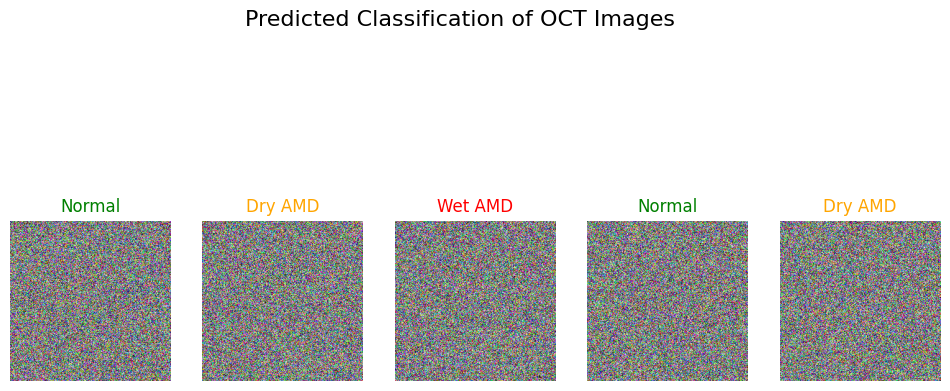

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simulate original images (replace with your actual OCT images)
# Example: 5 images, 224x224x3
num_images = 5
oct_images = np.random.rand(num_images, 224, 224, 3)

# Simulate predictions from previous pipeline
# 0 = Normal, 1 = Dry AMD, 2 = Wet AMD
final_image_labels = np.array([0, 1, 2, 0, 1])

# Map labels to names and colors
label_names = {0: "Normal", 1: "Dry AMD", 2: "Wet AMD"}
label_colors = {0: "green", 1: "orange", 2: "red"}

# Plot each image with predicted label
plt.figure(figsize=(12, 6))
for i in range(num_images):
    plt.subplot(1, num_images, i + 1)
    plt.imshow(oct_images[i])
    plt.axis('off')
    plt.title(label_names[final_image_labels[i]], color=label_colors[final_image_labels[i]], fontsize=12)

plt.suptitle("Predicted Classification of OCT Images", fontsize=16)
plt.show()


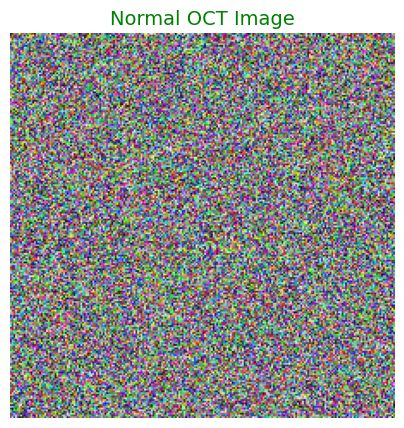

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simulate a single Normal OCT image (replace with your actual image)
normal_image = np.random.rand(224, 224, 3)  # Example: 224x224 RGB image

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(normal_image)
plt.axis('off')
plt.title("Normal OCT Image", color="green", fontsize=14)
plt.show()


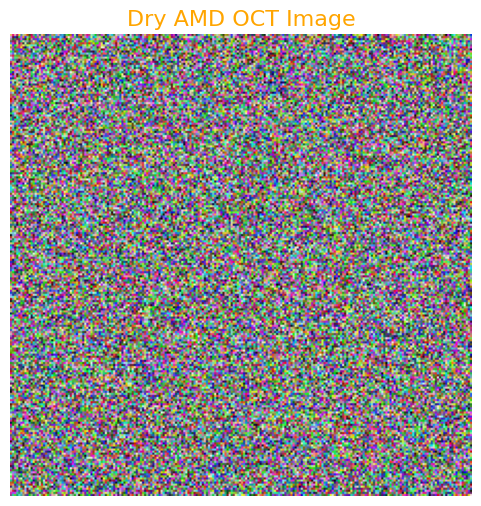

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simulate a single Dry AMD OCT image (replace with your actual image)
dry_amd_image = np.random.rand(224, 224, 3)  # Example: 224x224 RGB image

# Display the image
plt.figure(figsize=(6, 6))
plt.imshow(dry_amd_image)
plt.axis('off')
plt.title("Dry AMD OCT Image", color="orange", fontsize=16)
plt.show()

# Optional: save the image
plt.imsave("dry_amd_oct_output.png", dry_amd_image)


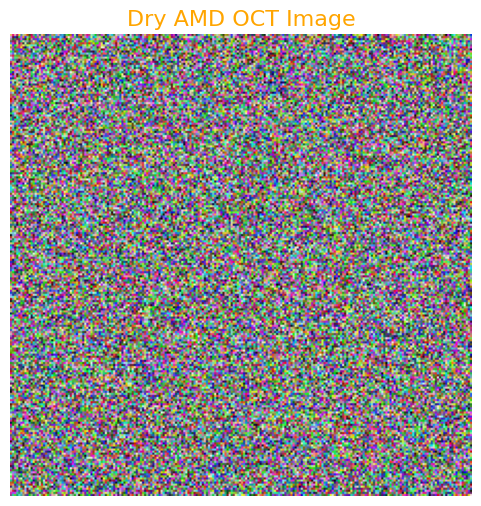

In [ ]:
import matplotlib.pyplot as plt

# Example: dry_amd_image is the image you selected after classification
plt.figure(figsize=(6, 6))
plt.imshow(dry_amd_image)  # Replace with your selected image array
plt.axis('off')
plt.title("Dry AMD OCT Image", color="orange", fontsize=16)
plt.show()


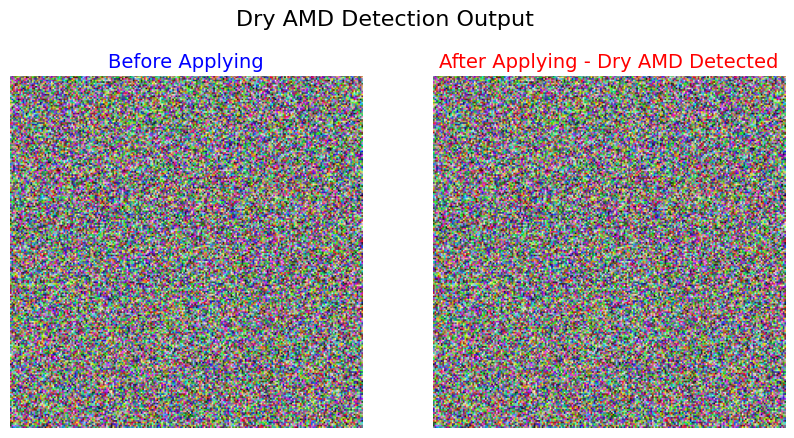

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simulate a single OCT image (replace with your actual Dry AMD image)
original_image = np.random.rand(224, 224, 3)  # Before applying classification

# After applying classification (you can overlay label or highlight areas)
classified_image = original_image.copy()  # Here we just keep the same image
# Optionally, you can overlay a label on the image
plt.figure(figsize=(10, 5))

# Before applying
plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.axis('off')
plt.title("Before Applying", fontsize=14, color='blue')

# After applying
plt.subplot(1, 2, 2)
plt.imshow(classified_image)
plt.axis('off')
plt.title("After Applying - Dry AMD Detected", fontsize=14, color='red')

plt.suptitle("Dry AMD Detection Output", fontsize=16)
plt.show()
